# Laboratorium: perceptron

**Podstawy AI**

Dziś zbudujesz od zera **perceptron** (Rosenblatt, 1957): najprostszy model, który *uczy się z danych*. Szuka on **prostej**, która oddziela dwie klasy punktów.

Plan:
1. implementacja reguły uczenia i sprawdzenie na przykładzie z kartki,
2. perceptron na danych Iris,
3. eksperyment: czy współczynnik uczenia $\eta$ ma znaczenie?
4. dane, których nie da się rozdzielić prostą,
5. XOR: czego jeden neuron nie potrafi.

**Jak pracujemy:** komórki oznaczone `# TODO` uzupełniasz sam. W eksperymentach stosujemy zasadę **przewiduję → uruchamiam → wyjaśniam**: najpierw zapisujesz, czego się spodziewasz, dopiero potem uruchamiasz kod.

**Na koniec:** wrzuć uzupełniony notebook na swojego GitHuba.

Notebook wzoruje się na rozdziale 2 książki S. Raschki *Machine Learning with PyTorch and Scikit-Learn*.

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris

np.set_printoptions(precision=3, suppress=True)

## 1. Perceptron — przypomnienie

Neuron liczy **pobudzenie** (ang. *net input*):

$$z = w_1 x_1 + w_2 x_2 + \dots + w_m x_m + b = \mathbf{w}^T\mathbf{x} + b$$

i zamienia je na klasę **funkcją skokową**:

$$\hat{y} = \begin{cases} 1 & \text{jeśli } z \ge 0 \\ 0 & \text{w przeciwnym razie} \end{cases}$$

**Uczenie.** Dla każdego przykładu $\mathbf{x}^{(i)}$ po kolei:

1. liczymy predykcję $\hat{y}^{(i)}$ (raz, na obecnych wagach),
2. liczymy błąd $e = y^{(i)} - \hat{y}^{(i)}$ (prawdziwa klasa **minus** przewidziana),
3. poprawiamy wszystkie wagi i bias:

$$w_j := w_j + \eta\, e\, x_j^{(i)}, \qquad b := b + \eta\, e$$

Gdy przewidywanie jest trafne, $e = 0$ i nic się nie zmienia. Gdy jest błędne, $e = \pm 1$ i wagi przesuwają się w stronę prawdziwej klasy. Jedno przejście przez cały zbiór to **epoka**.

### Zadanie 1 — uzupełnij metodę `fit`

Poniżej jest prawie gotowa klasa `Perceptron`. Brakuje **trzech linijek** w pętli uczącej: obliczenia poprawki `update` $= \eta \cdot e$ i dodania jej do wag `self.w_` oraz biasu `self.b_`.

Wskazówki:
- `xi` to wektor cech jednego przykładu (tablica NumPy), `target` to jego prawdziwa klasa $y$,
- `self.predict(xi)` zwraca predykcję $\hat{y}$,
- `update * xi` mnoży poprawkę przez *każdą* cechę naraz, więc poprawia wszystkie wagi jednocześnie,
- `update` licz **przed** zmianą wag, bo $\hat y$ ma pochodzić ze starych wag.

Parametr `verbose=True` wypisuje każdy krok uczenia, tak jak w tabelce, którą liczyłeś na kartce.

In [34]:
class Perceptron:
    """Klasyfikator perceptronowy (etykiety 0/1).

    Parametry
    ---------
    eta : float        współczynnik uczenia (0.0 – 1.0)
    n_iter : int       liczba epok
    w_init : str       'zeros' (wagi startowe = 0) albo 'random' (małe losowe)
    random_state : int ziarno generatora liczb losowych
    verbose : bool     czy wypisywać każdy krok uczenia

    Atrybuty po uczeniu
    -------------------
    w_ : wagi,  b_ : bias,  errors_ : liczba pomyłek w każdej epoce
    """

    def __init__(self, eta=0.1, n_iter=10, w_init="random", random_state=1, verbose=False):
        self.eta = eta
        self.n_iter = n_iter
        self.w_init = w_init
        self.random_state = random_state
        self.verbose = verbose
        #self.errors_ = []

    def fit(self, X, y):
        n_cech = X.shape[1]
        if self.w_init == "zeros":
            self.w_ = np.zeros(n_cech)
        else:
            rgen = np.random.RandomState(self.random_state)
            self.w_ = rgen.normal(loc=0.0, scale=0.01, size=n_cech)
        self.b_ = 0.0
        self.errors_ = []

        for epoka in range(1, self.n_iter + 1):
            bledy = 0
            for xi, target in zip(X, y):
                if self.verbose:
                    w_przed, b_przed = self.w_.copy(), self.b_
                    z, y_hat = self.net_input(xi), self.predict(xi)
                # TODO: uzupełnij trzy linijki
                update = self.eta * (target - self.predict(xi))
                self.w_ += update * xi
                self.b_ += update
                bledy += int(update != 0.0)
                if self.verbose:
                    print(f"epoka {epoka} | x={xi} y={target} | w={w_przed} b={b_przed:5.2f} "
                          f"| z={z:6.2f} ŷ={y_hat} | update={update:+.2f}")
            self.errors_.append(bledy)
            if self.verbose:
                print(f"--- koniec epoki {epoka}: pomyłek {bledy}, w={self.w_}, b={self.b_:.2f}")
        return self

    def net_input(self, X):
        """Pobudzenie z = w^T x + b"""
        return np.dot(X, self.w_) + self.b_

    def predict(self, X):
        """Funkcja skokowa: 1 jeśli z >= 0, w przeciwnym razie 0"""
        return np.where(self.net_input(X) >= 0.0, 1, 0)

## 2. Sprawdzenie na przykładzie z kartki

Na zajęciach liczyłeś ręcznie perceptron dla czterech punktów, startując od $w_1 = w_2 = b = 0$ i $\eta = 1$:

| punkt | $x_1$ | $x_2$ | $y$ |
|---|---|---|---|
| A | 2 | 1 | 1 |
| B | 1 | 3 | 0 |
| C | 3 | 2 | 1 |
| D | 0 | 2 | 0 |

Uruchom swój perceptron na tych danych. **Wypisane kroki muszą zgadzać się z Twoją tabelką na kartce.**

In [35]:
X_kartka = np.array([[2, 1], [1, 3], [3, 2], [0, 2]], dtype=float)
y_kartka = np.array([1, 0, 1, 0])

p = Perceptron(eta=1.0, n_iter=3, w_init="zeros", verbose=True)
p.fit(X_kartka, y_kartka)

epoka 1 | x=[2. 1.] y=1 | w=[0. 0.] b= 0.00 | z=  0.00 ŷ=1 | update=+0.00
epoka 1 | x=[1. 3.] y=0 | w=[0. 0.] b= 0.00 | z=  0.00 ŷ=1 | update=-1.00
epoka 1 | x=[3. 2.] y=1 | w=[-1. -3.] b=-1.00 | z=-10.00 ŷ=0 | update=+1.00
epoka 1 | x=[0. 2.] y=0 | w=[ 2. -1.] b= 0.00 | z= -2.00 ŷ=0 | update=+0.00
--- koniec epoki 1: pomyłek 2, w=[ 2. -1.], b=0.00
epoka 2 | x=[2. 1.] y=1 | w=[ 2. -1.] b= 0.00 | z=  3.00 ŷ=1 | update=+0.00
epoka 2 | x=[1. 3.] y=0 | w=[ 2. -1.] b= 0.00 | z= -1.00 ŷ=0 | update=+0.00
epoka 2 | x=[3. 2.] y=1 | w=[ 2. -1.] b= 0.00 | z=  4.00 ŷ=1 | update=+0.00
epoka 2 | x=[0. 2.] y=0 | w=[ 2. -1.] b= 0.00 | z= -2.00 ŷ=0 | update=+0.00
--- koniec epoki 2: pomyłek 0, w=[ 2. -1.], b=0.00
epoka 3 | x=[2. 1.] y=1 | w=[ 2. -1.] b= 0.00 | z=  3.00 ŷ=1 | update=+0.00
epoka 3 | x=[1. 3.] y=0 | w=[ 2. -1.] b= 0.00 | z= -1.00 ŷ=0 | update=+0.00
epoka 3 | x=[3. 2.] y=1 | w=[ 2. -1.] b= 0.00 | z=  4.00 ŷ=1 | update=+0.00
epoka 3 | x=[0. 2.] y=0 | w=[ 2. -1.] b= 0.00 | z= -2.00 ŷ=0 | upd

In [36]:
# Test: jeśli ta komórka nie zgłasza błędu, Twoja implementacja jest poprawna
assert np.allclose(p.w_, [2, -1]) and np.isclose(p.b_, 0), f"Coś nie tak: w={p.w_}, b={p.b_}"
assert p.errors_ == [2, 0, 0]
print("✅ Wynik zgodny z kartką: w =", p.w_, " b =", p.b_)

✅ Wynik zgodny z kartką: w = [ 2. -1.]  b = 0.0


Narysujmy punkty z kartki i granicę decyzyjną. Granica to punkty, dla których $z = 0$:

$$w_1 x_1 + w_2 x_2 + b = 0 \quad\Longrightarrow\quad x_2 = -\frac{w_1 x_1 + b}{w_2}$$

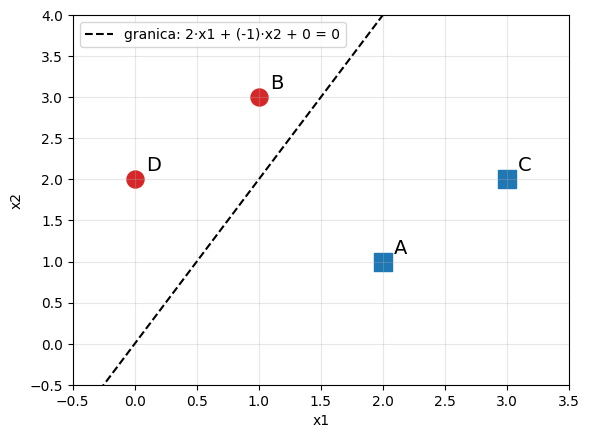

In [37]:
x1 = np.linspace(-0.5, 3.5, 2)
x2 = -(p.w_[0] * x1 + p.b_) / p.w_[1]          # prosta z = 0

plt.plot(x1, x2, "k--", label=f"granica: {p.w_[0]:.0f}·x1 + ({p.w_[1]:.0f})·x2 + {p.b_:.0f} = 0")
for nazwa, (a, b), klasa in zip("ABCD", X_kartka, y_kartka):
    plt.scatter(a, b, s=150, color="tab:blue" if klasa else "tab:red", marker="s" if klasa else "o")
    plt.annotate(nazwa, (a, b), xytext=(8, 6), textcoords="offset points", fontsize=14)
plt.xlim(-0.5, 3.5); plt.ylim(-0.5, 4); plt.grid(alpha=0.3)
plt.xlabel("x1"); plt.ylabel("x2"); plt.legend(); plt.show()

**Pytanie 1.** Po aktualizacji na punkcie B punkt C ma $z = -10$, czyli jest bardzo źle sklasyfikowany (zobacz wydruk). Co to mówi o sposobie, w jaki uczy się perceptron?

✍️ **Twoja odpowiedź:** ...

Perceptron nie może nauczyć się w jednym przebiegu, dlatego potrzebuje przejść przez kilka epok (w tym przypadku dwie) aż do momentu ustabilizowania. W dalszych etapach obserwujemy wartości z już dużo bliższe zera.

## 3. Dane: kwiaty irysa

Zbiór Iris zawiera pomiary 150 kwiatów z trzech gatunków: setosa (kwiaty 0–49), versicolor (50–99) i virginica (100–149). Na początek bierzemy:
- **dwa gatunki**: setosa (klasa 0) i versicolor (klasa 1), czyli pierwsze 100 kwiatów,
- **dwie cechy**: długość działki kielicha (kolumna 0) i długość płatka (kolumna 2).

Dwie cechy wybieramy po to, żeby wszystko dało się narysować na płaszczyźnie.

Kształt X: (100, 2)  Liczba przykładów w klasach: [50 50]


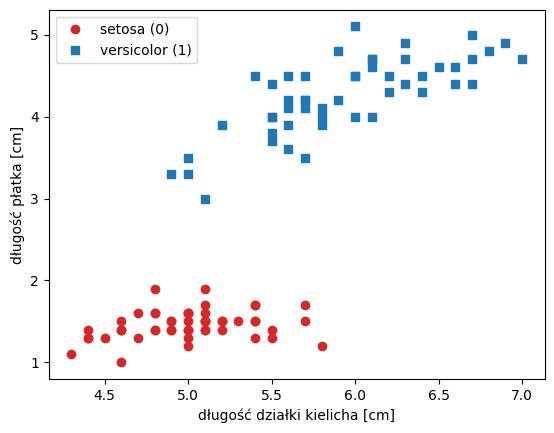

In [38]:
iris = load_iris()
X = iris.data[:100][:, [0, 2]]               # 100 kwiatów, cechy: działka, płatek [cm]
y = (iris.target[:100] == 1).astype(int)      # setosa -> 0, versicolor -> 1

print("Kształt X:", X.shape, " Liczba przykładów w klasach:", np.bincount(y))

plt.scatter(X[y == 0, 0], X[y == 0, 1], color="tab:red", marker="o", label="setosa (0)")
plt.scatter(X[y == 1, 0], X[y == 1, 1], color="tab:blue", marker="s", label="versicolor (1)")
plt.xlabel("długość działki kielicha [cm]")
plt.ylabel("długość płatka [cm]")
plt.legend(loc="upper left")
plt.show()

Funkcja pomocnicza do rysowania **regionów decyzyjnych**: koloruje każdy punkt płaszczyzny według tego, jaką klasę przewiduje model. Granica między kolorami to granica decyzyjna. Nie musisz jej modyfikować.

In [39]:
def plot_decision_regions(X, y, model, resolution=0.02, ax=None, title=None, etykiety=("klasa 0", "klasa 1")):
    ax = ax or plt.gca()
    cmap = ListedColormap(["tab:red", "tab:blue"])
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    siatka = np.array([xx1.ravel(), xx2.ravel()]).T          # wszystkie punkty siatki
    Z = model.predict(siatka).reshape(xx1.shape)             # klasa dla każdego punktu
    ax.contourf(xx1, xx2, Z, alpha=0.25, cmap=cmap)
    for klasa, kolor, marker in [(0, "tab:red", "o"), (1, "tab:blue", "s")]:
        ax.scatter(X[y == klasa, 0], X[y == klasa, 1], c=kolor, marker=marker,
                   edgecolor="black", label=etykiety[klasa])
    ax.set_xlim(x1_min, x1_max); ax.set_ylim(x2_min, x2_max)
    if title: ax.set_title(title)
    ax.legend(loc="upper left")

## 4. Uczymy perceptron na Iris

### Zadanie 2
Naucz perceptron (`eta=0.1`, `n_iter=10`) na danych `X`, `y`. Następnie narysuj obok siebie:
1. liczbę pomyłek w każdej epoce (atrybut `errors_`),
2. regiony decyzyjne (funkcja `plot_decision_regions`).

epoka 1 | x=[5.1 1.4] y=0 | w=[0. 0.] b= 0.00 | z=  0.00 ŷ=1 | update=-0.10
epoka 1 | x=[4.9 1.4] y=0 | w=[-0.51 -0.14] b=-0.10 | z= -2.80 ŷ=0 | update=+0.00
epoka 1 | x=[4.7 1.3] y=0 | w=[-0.51 -0.14] b=-0.10 | z= -2.68 ŷ=0 | update=+0.00
epoka 1 | x=[4.6 1.5] y=0 | w=[-0.51 -0.14] b=-0.10 | z= -2.66 ŷ=0 | update=+0.00
epoka 1 | x=[5.  1.4] y=0 | w=[-0.51 -0.14] b=-0.10 | z= -2.85 ŷ=0 | update=+0.00
epoka 1 | x=[5.4 1.7] y=0 | w=[-0.51 -0.14] b=-0.10 | z= -3.09 ŷ=0 | update=+0.00
epoka 1 | x=[4.6 1.4] y=0 | w=[-0.51 -0.14] b=-0.10 | z= -2.64 ŷ=0 | update=+0.00
epoka 1 | x=[5.  1.5] y=0 | w=[-0.51 -0.14] b=-0.10 | z= -2.86 ŷ=0 | update=+0.00
epoka 1 | x=[4.4 1.4] y=0 | w=[-0.51 -0.14] b=-0.10 | z= -2.54 ŷ=0 | update=+0.00
epoka 1 | x=[4.9 1.5] y=0 | w=[-0.51 -0.14] b=-0.10 | z= -2.81 ŷ=0 | update=+0.00
epoka 1 | x=[5.4 1.5] y=0 | w=[-0.51 -0.14] b=-0.10 | z= -3.06 ŷ=0 | update=+0.00
epoka 1 | x=[4.8 1.6] y=0 | w=[-0.51 -0.14] b=-0.10 | z= -2.77 ŷ=0 | update=+0.00
epoka 1 | x=[4.8 1.4] 

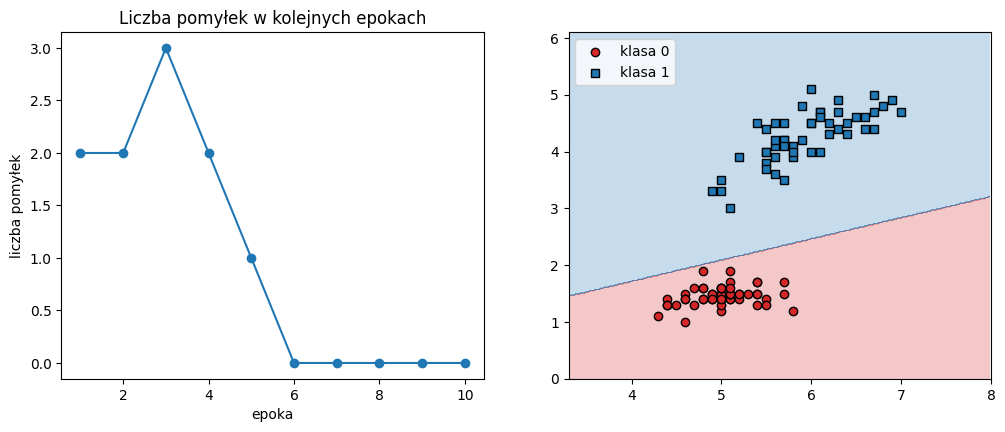

In [40]:
# TODO: utwórz perceptron i naucz go na X, y
ppn = Perceptron(eta=0.1, n_iter=10, w_init="zeros", verbose=True)
ppn.fit(X, y)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))

# TODO: na axs[0] wykres liczby pomyłek w kolejnych epokach
# TODO: na axs[1] regiony decyzyjne: plot_decision_regions(X, y, ppn, ax=axs[1])

axs[0].plot(range(1, len(ppn.errors_) + 1), ppn.errors_, marker="o")
plot_decision_regions(X, y, ppn, ax=axs[1])
axs[0].set_xlabel("epoka"); axs[0].set_ylabel("liczba pomyłek")
axs[0].set_title("Liczba pomyłek w kolejnych epokach")

plt.show()

**Pytanie 2.** Po ilu epokach perceptron przestał się mylić? Czy granica decyzyjna leży „w środku” między klasami, czy blisko jednej z nich? Dlaczego perceptronowi jest wszystko jedno, gdzie dokładnie leży granica?

✍️ **Twoja odpowiedź:** ...

Perceptron przestał się mylić po 6 epokach, a granica leży dużo bliżej klasy 0. Dla perceptronu nie ma znaczenia, gdzie dokładnie leży granica ze względu na to, że reguła uczenia perceptronu opiera się wyłącznie na błędzie klasyfikacji. Poprawki wag i biasu są nanoszone tylko wtedy, gdy model popełni błąd. Gdy wszystkie punkty zostaną poprawnie sklasyfikowane (czyli znajdą się po właściwej stronie granicy), błąd wynosi 0, algorytm przestaje aktualizować wagi i kończy działanie.

## 5. Eksperyment: czy $\eta$ ma znaczenie?

### 5a. Najpierw kartka

Policz jeszcze raz przykład z kartki, ale z $\eta = 0.5$. Porównaj wydruk z wydrukiem dla $\eta = 1$ z punktu 2: co się zmieniło, a co nie?

In [41]:
p_half = Perceptron(eta=0.5, n_iter=2, w_init="zeros", verbose=True).fit(X_kartka, y_kartka)

epoka 1 | x=[2. 1.] y=1 | w=[0. 0.] b= 0.00 | z=  0.00 ŷ=1 | update=+0.00
epoka 1 | x=[1. 3.] y=0 | w=[0. 0.] b= 0.00 | z=  0.00 ŷ=1 | update=-0.50
epoka 1 | x=[3. 2.] y=1 | w=[-0.5 -1.5] b=-0.50 | z= -5.00 ŷ=0 | update=+0.50
epoka 1 | x=[0. 2.] y=0 | w=[ 1.  -0.5] b= 0.00 | z= -1.00 ŷ=0 | update=+0.00
--- koniec epoki 1: pomyłek 2, w=[ 1.  -0.5], b=0.00
epoka 2 | x=[2. 1.] y=1 | w=[ 1.  -0.5] b= 0.00 | z=  1.50 ŷ=1 | update=+0.00
epoka 2 | x=[1. 3.] y=0 | w=[ 1.  -0.5] b= 0.00 | z= -0.50 ŷ=0 | update=+0.00
epoka 2 | x=[3. 2.] y=1 | w=[ 1.  -0.5] b= 0.00 | z=  2.00 ŷ=1 | update=+0.00
epoka 2 | x=[0. 2.] y=0 | w=[ 1.  -0.5] b= 0.00 | z= -1.00 ŷ=0 | update=+0.00
--- koniec epoki 2: pomyłek 0, w=[ 1.  -0.5], b=0.00


**Pytanie 3.** Porównaj kolumny `z`, `ŷ` i końcowe wagi dla $\eta = 1$ i $\eta = 0.5$. Czy granica decyzyjna jest inna?

✍️ **Twoja odpowiedź:**

Dla $\eta = 1$ mieliśmy takie wyniki:

| Epoka | Przykład $x$ | Klasa $y$ | Wagi startowe $w$ | Bias $b$ | Pobudzenie $z$ | Predykcja $\hat{y}$ | Poprawka (update) |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **1** | `[2. 1.]` | 1 | `[0. 0.]` | 0.00 | 0.00 | 1 | +0.00 |
| **1** | `[1. 3.]` | 0 | `[0. 0.]` | 0.00 | 0.00 | 1 | -1.00 |
| **1** | `[3. 2.]` | 1 | `[-1. -3.]` | -1.00 | -10.00 | 0 | +1.00 |
| **1** | `[0. 2.]` | 0 | `[2. -1.]` | 0.00 | -2.00 | 0 | +0.00 |
| *Koniec 1* | | | **Końcowe $w$:** `[2. -1.]` | **Końcowy $b$:** 0.00 | | | **Pomyłki: 2** |
| **2** | `[2. 1.]` | 1 | `[2. -1.]` | 0.00 | 3.00 | 1 | +0.00 |
| **2** | `[1. 3.]` | 0 | `[2. -1.]` | 0.00 | -1.00 | 0 | +0.00 |
| **2** | `[3. 2.]` | 1 | `[2. -1.]` | 0.00 | 4.00 | 1 | +0.00 |
| **2** | `[0. 2.]` | 0 | `[2. -1.]` | 0.00 | -2.00 | 0 | +0.00 |
| *Koniec 2* | | | **Końcowe $w$:** `[2. -1.]` | **Końcowy $b$:** 0.00 | | | **Pomyłki: 0** |

Porównując je z wynikami dla $\eta = 0.5$ obserwujemy, że wartości z od razu są dużo bliższe zera, punkty są lepiej sklasyfikowane, natomiast ŷ się nie różni. Końcowe wagi i bias różnią się, jednak granica decyzyjna pozostaje bez zmian.
Dzieje się tak, ponieważ przy zerowych wagach startowych, zmniejszenie $\eta$ o połowę (z $1.0$ do $0.5$) skutkuje dokładnie dwukrotnym zmniejszeniem końcowych wag i biasu. Równanie granicy decyzyjnej $0.5w_1x_1 + 0.5w_2x_2 + 0.5b = 0$ po podzieleniu obustronnie przez $0.5$ sprowadza się do wyjściowego równania $w_1x_1 + w_2x_2 + b = 0$, co oznacza tę samą prostą.

### 5b. Teraz Iris

Naucz perceptron na Iris z czterema wartościami $\eta \in \{0.0001,\ 0.01,\ 0.1,\ 1\}$, **startując od zerowych wag** (`w_init="zeros"`).

**Przewiduję:** przy którym $\eta$ perceptron nauczy się najszybciej (najmniej epok do zera pomyłek)?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):** ...

Stawiam na najniższe η = 0.0001, we wcześniejszym przypadku mniejsze η miało lepiej sklasyfikowane punkty.

η = 0.0001  pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]   w/η = [-3.4  9.1],  b/η = -2.00
η = 0.01    pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]   w/η = [-3.4  9.1],  b/η = -2.00
η = 0.1     pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]   w/η = [-3.4  9.1],  b/η = -2.00
η = 1.0     pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]   w/η = [-3.4  9.1],  b/η = -2.00


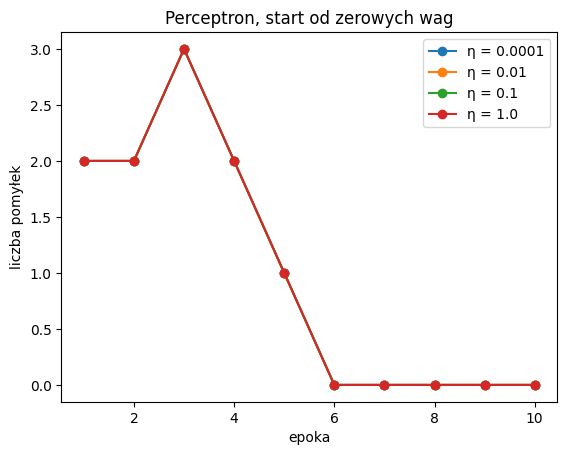

In [42]:
etas = [0.0001, 0.01, 0.1, 1.0]

for eta in etas:
    p = Perceptron(eta=eta, n_iter=10, w_init="zeros").fit(X, y)
    plt.plot(range(1, 11), p.errors_, marker="o", label=f"η = {eta}")
    print(f"η = {eta:<7} pomyłki: {p.errors_}   w/η = {p.w_ / eta},  b/η = {p.b_ / eta:.2f}")

plt.xlabel("epoka"); plt.ylabel("liczba pomyłek")
plt.title("Perceptron, start od zerowych wag"); plt.legend(); plt.show()

Wszystkie linie leżą na sobie. Spójrz na kolumnę `w/η`: jest **identyczna** dla każdego $\eta$.

**Pytanie 4.** Wyjaśnij, dlaczego przy zerowych wagach startowych $\eta$ nie ma wpływu na uczenie perceptronu. Wskazówka: od czego zależy predykcja $\hat{y}$ — od wartości $z$ czy tylko od jej znaku?

✍️ **Twoja odpowiedź:**

Przy starcie od zerowych wag współczynnik uczenia $\eta$ (dla $\eta > 0$) skaluje wagi i bias liniowo, co oznacza, że w każdym kroku $\mathbf{w}_{\eta} = \eta \cdot \mathbf{w}_{1.0}$ oraz $b_{\eta} = \eta \cdot b_{1.0}$.

W konsekwencji pobudzenie $z$ jest również przeskalowane o tę samą wartość: $z_{\eta} = \eta \cdot z_{1.0}$. Ponieważ $\eta$ jest dodatnie, pomnożenie przez nie nie wpływa na znak pobudzenia $z$.

Predykcja $\hat{y}$ zależy wyłącznie od znaku pobudzenia $z$ (funkcja skokowa), a nie od jego wartości bezwzględnej. Dlatego dla każdego $\eta$ model generuje identyczne predykcje, popełnia te same błędy w tych samych momentach i uczy się w dokładnie taki sam sposób.

### 5c. Losowe wagi startowe

To samo, ale z **małymi losowymi wagami startowymi** (domyślne `w_init="random"`, jak u Raschki; wagi są losowane z rozkładu normalnego o odchyleniu 0.01).

η = 0.0001  pomyłki: [34, 16, 13, 11, 10, 8, 6, 5, 5, 5]
η = 0.01    pomyłki: [2, 2, 3, 1, 0, 0, 0, 0, 0, 0]
η = 0.1     pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]
η = 1.0     pomyłki: [2, 2, 3, 2, 1, 0, 0, 0, 0, 0]


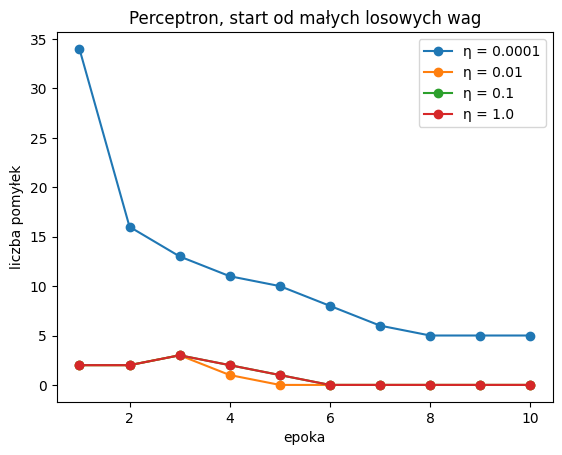

In [43]:
for eta in etas:
    p = Perceptron(eta=eta, n_iter=10, w_init="random").fit(X, y)
    plt.plot(range(1, 11), p.errors_, marker="o", label=f"η = {eta}")
    print(f"η = {eta:<7} pomyłki: {p.errors_}")
plt.xlabel("epoka"); plt.ylabel("liczba pomyłek")
plt.title("Perceptron, start od małych losowych wag"); plt.legend(); plt.show()

**Pytanie 5.** Dlaczego teraz najmniejsze $\eta = 0.0001$ uczy się wyraźnie wolniej, a pozostałe prawie tak samo?


✍️ **Twoja odpowiedź:**

Dla bardzo małego $\eta = 0.0001$ pojedyncze poprawki (np. $\eta \cdot x \approx 0.0001 \cdot 5 = 0.0005$) są znacznie mniejsze niż te losowe wagi początkowe. Model potrzebuje bardzo wielu kroków, aby skumulowane poprawki zdominowały początkowy losowy „szum” i odpowiednio obróciły granicę decyzyjną.

Dla większych wartości $\eta$ (np. $0.01, 0.1, 1.0$) poprawka jest na tyle duża (równa lub wielokrotnie większa od $0.01$), że losowe wartości startowe tracą znaczenie już po pierwszej aktualizacji, a proces uczenia przebiega bardzo szybko.

## 6. Gdy klas nie da się rozdzielić prostą

Weźmy teraz inną parę gatunków: **versicolor** (klasa 0) i **virginica** (klasa 1), czyli kwiaty o indeksach 50–149, z tymi samymi dwiema cechami.

**Przewiduję:** po ilu epokach perceptron przestanie się mylić?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):** ...

### Zadanie 3
1. Utwórz `X2` (kwiaty 50–149, kolumny 0 i 2) i `y2` (1 dla virginica, 0 dla versicolor). Wskazówka: virginica ma w `iris.target` wartość 2.
2. **Przetasuj dane** (kod jest podany). W zbiorze Iris kwiaty są posortowane według gatunku: najpierw 50 versicolor, potem 50 virginica. Bez tasowania perceptron widzi 50 kwiatów jednej klasy z rzędu i dopasowuje się tylko do ostatnio oglądanej.
3. Naucz perceptron (`eta=0.1`, `n_iter=30`) i narysuj liczbę pomyłek w epokach oraz regiony decyzyjne.
4. Policz, ile pomyłek robi **nauczony model** (po ostatniej epoce) na całym zbiorze: `(ppn2.predict(X2) != y2).sum()`.

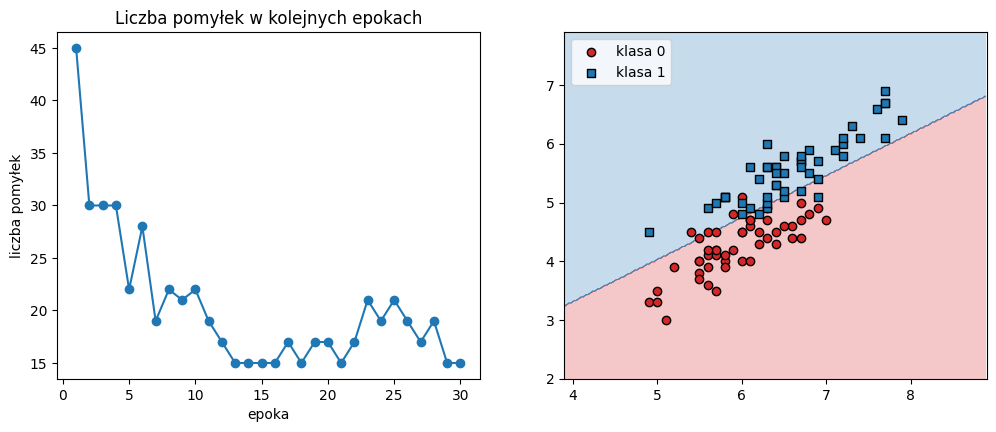

Liczba pomyłek na zbiorze: 10


In [44]:
# TODO: dane
X2 = iris.data[50:149][:, [0, 2]]
y2 = (iris.target[50:149] == 2).astype(int)



# tasowanie (gotowe): ta sama losowa kolejność dla X2 i y2
idx = np.random.RandomState(0).permutation(len(y2))
X2, y2 = X2[idx], y2[idx]

# TODO: perceptron, 30 epok, wykres pomyłek i regionów decyzyjnych
# TODO: liczba pomyłek nauczonego modelu

perc = Perceptron(eta=0.1, n_iter=30).fit(X2, y2)

ig, axs = plt.subplots(1, 2, figsize=(12, 4.5))

axs[0].plot(range(1, len(perc.errors_) + 1), perc.errors_, marker="o")
plot_decision_regions(X2, y2, perc, ax=axs[1])
axs[0].set_xlabel("epoka"); axs[0].set_ylabel("liczba pomyłek")
axs[0].set_title("Liczba pomyłek w kolejnych epokach")

plt.show()

liczba_pomylek = 0

liczba_pomylek = (perc.predict(X2) != y2).sum()
print(f"Liczba pomyłek na zbiorze: {liczba_pomylek}")

Sprawdźmy jeszcze, co się dzieje z wagami, gdy uczymy dłużej.

In [45]:
for n in [10, 20, 30, 100]:
    p = Perceptron(eta=0.1, n_iter=n).fit(X2, y2)
    print(f"po {n:>3} epokach: w = {p.w_},  b = {p.b_:5.2f},  "
          f"pomyłki w ostatniej epoce: {p.errors_[-1]:>2},  pomyłki modelu: {(p.predict(X2) != y2).sum()}")

po  10 epokach: w = [-4.204  5.234],  b = -1.90,  pomyłki w ostatniej epoce: 22,  pomyłki modelu: 28
po  20 epokach: w = [-5.214  7.484],  b = -2.90,  pomyłki w ostatniej epoce: 17,  pomyłki modelu: 10
po  30 epokach: w = [-6.294  8.784],  b = -3.90,  pomyłki w ostatniej epoce: 15,  pomyłki modelu: 10
po 100 epokach: w = [-8.044 11.934],  b = -9.40,  pomyłki w ostatniej epoce: 15,  pomyłki modelu: 11


**Pytanie 6.** Czy perceptron kiedykolwiek przestaje się mylić? Co dzieje się z wagami? Co to oznacza dla „wyniku” uczenia? Dlaczego liczba pomyłek *w trakcie* epoki (`errors_`) jest inna niż liczba pomyłek *nauczonego modelu*?

✍️ **Twoja odpowiedź:**

Perceptron nie przestaje się mylić, ponieważ klasy nakładają się na siebie i żadna prosta nie jest w stanie idealnie ich oddzielić.

Wagi i bias stale rosną co do wartości bezwzględnej i nieustannie oscylują. Model ciągle modyfikuje wagi pod wpływem napotykanych błędów.

Proces uczenia nie jest zbieżny. Końcowa prosta decyzyjna zależy od momentu zatrzymania algorytmu (liczby epok).

Liczba pomyłek w trakcie epoki jest liczona na zmieniających się dynamicznie wagach (pojedyncze poprawki po każdym błędzie). Liczba pomyłek modelu po zakończeniu uczenia jest liczona na stałych, zamrożonych wagach uzyskanych na koniec epoki.

## 7. XOR: czego jeden neuron nie potrafi

Funkcja **XOR** („albo, albo”) daje 1, gdy *dokładnie jedno* z dwóch wejść jest równe 1:

| $x_1$ | $x_2$ | AND | OR | **XOR** |
|---|---|---|---|---|
| 0 | 0 | 0 | 0 | **0** |
| 1 | 0 | 0 | 1 | **1** |
| 0 | 1 | 0 | 1 | **1** |
| 1 | 1 | 1 | 1 | **0** |

### Zadanie 4
1. Utwórz `X_log` (4 punkty z tabeli) oraz etykiety `y_and`, `y_or`, `y_xor`.
2. Naucz perceptron (`eta=0.1`, `n_iter=20`, `w_init="zeros"`) osobno dla AND, OR i XOR.
3. Wypisz liczbę pomyłek w epokach dla każdej funkcji i narysuj ją na jednym wykresie.

**Przewiduję:** których funkcji perceptron się nauczy?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):** ...

Przewiduję AND oraz OR. XOR raczej też, ale nie jestem pewna.

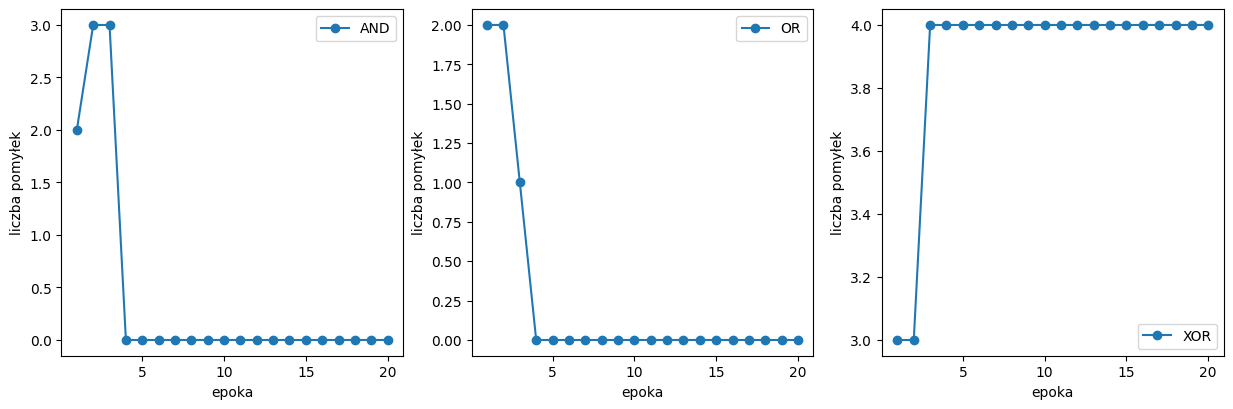

In [46]:
# TODO: dane
X_log = np.array([[0,0], [1, 0], [0, 1],[1,1]])
y_and = np.array([0, 0, 0, 1])
y_or  = np.array([0, 1, 1, 1])
y_xor = np.array([0, 1, 1, 0])

# TODO: trzy perceptrony i wykres pomyłek

p_and = Perceptron(eta=0.1, n_iter=20, w_init="zeros").fit(X_log, y_and)
p_or  = Perceptron(eta=0.1, n_iter=20, w_init="zeros").fit(X_log, y_or)
p_xor = Perceptron(eta=0.1, n_iter=20, w_init="zeros").fit(X_log, y_xor)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
axs[0].plot(range(1, 21), p_and.errors_, marker="o", label="AND")
axs[1].plot(range(1, 21), p_or.errors_, marker="o", label="OR")
axs[2].plot(range(1, 21), p_xor.errors_, marker="o", label="XOR")

#axs[0].set_xlabel("epoka"); axs[0].set_ylabel("liczba pomyłek")

for i in [0, 1, 2]:
    axs[i].set_xlabel("epoka")
    axs[i].set_ylabel("liczba pomyłek")
    axs[i].legend()

plt.show()

Zobacz krok po kroku, co robi perceptron na XOR w pierwszych trzech epokach:

In [47]:
_ = Perceptron(eta=0.1, n_iter=3, w_init="zeros", verbose=True).fit(X_log, np.array([0, 1, 1, 0]))

epoka 1 | x=[0 0] y=0 | w=[0. 0.] b= 0.00 | z=  0.00 ŷ=1 | update=-0.10
epoka 1 | x=[1 0] y=1 | w=[0. 0.] b=-0.10 | z= -0.10 ŷ=0 | update=+0.10
epoka 1 | x=[0 1] y=1 | w=[0.1 0. ] b= 0.00 | z=  0.00 ŷ=1 | update=+0.00
epoka 1 | x=[1 1] y=0 | w=[0.1 0. ] b= 0.00 | z=  0.10 ŷ=1 | update=-0.10
--- koniec epoki 1: pomyłek 3, w=[ 0.  -0.1], b=-0.10
epoka 2 | x=[0 0] y=0 | w=[ 0.  -0.1] b=-0.10 | z= -0.10 ŷ=0 | update=+0.00
epoka 2 | x=[1 0] y=1 | w=[ 0.  -0.1] b=-0.10 | z= -0.10 ŷ=0 | update=+0.10
epoka 2 | x=[0 1] y=1 | w=[ 0.1 -0.1] b= 0.00 | z= -0.10 ŷ=0 | update=+0.10
epoka 2 | x=[1 1] y=0 | w=[0.1 0. ] b= 0.10 | z=  0.20 ŷ=1 | update=-0.10
--- koniec epoki 2: pomyłek 3, w=[ 0.  -0.1], b=0.00
epoka 3 | x=[0 0] y=0 | w=[ 0.  -0.1] b= 0.00 | z=  0.00 ŷ=1 | update=-0.10
epoka 3 | x=[1 0] y=1 | w=[ 0.  -0.1] b=-0.10 | z= -0.10 ŷ=0 | update=+0.10
epoka 3 | x=[0 1] y=1 | w=[ 0.1 -0.1] b= 0.00 | z= -0.10 ŷ=0 | update=+0.10
epoka 3 | x=[1 1] y=0 | w=[0.1 0. ] b= 0.10 | z=  0.20 ŷ=1 | update=-0.

**Pytanie 7.** AND i OR działają, XOR nie. Narysuj na kartce 4 punkty XOR i spróbuj poprowadzić jedną prostą, która oddzieli klasę 1 od klasy 0. Dlaczego się nie da? Co widać w wydruku powyżej: co dzieje się z wagami z epoki na epokę?

✍️ **Twoja odpowiedź:** ...

Każda pojedyncza prosta, która spróbuje odciąć klasę 1 od 0, zawsze zostawi co najmniej jeden punkt po złej stronie. Nie istnieje taka prosta, która mogłaby oddzielić te dwie klasy.

Wagi oraz bias wchodzą w pętlę i zaczynają się powtarzać cyklicznie (np. na końcu epoki 2 i epoki 3 wagi wynoszą dokładnie tyle samo). Perceptron wpada w permanentne oscylacje – poprawienie błędu na jednym punkcie psuje klasyfikację na innym, przez co model kręci się w kółko i nigdy nie osiągnie zbieżności.

## 8. Podsumowanie

Odpowiedz krótko własnymi słowami (kliknij dwukrotnie, żeby edytować):

1. Co oznacza geometrycznie zbiór punktów, dla których $z = 0$?
* Jest to granica decyzyjna, czyli prosta dzielącą przestrzeń na dwa obszary, w których znajdują się dane klasy.

2. Kiedy perceptron zmienia wagi, a kiedy nie?
* Jest to uzależnione od tego, czy perceptron popełni błąd (czy jego przewidywanie się spełniło). Jeżeli przewidzi klasę poprawnie, nie ma potrzeby dokonania poprawy, a wagi się nie zmieniają.

3. Dlaczego przy starcie od zera $\eta$ nie zmienia granicy?
* Współczynnik uczenia, jeżeli zaczynamy od samych zer, proporcjonalnie skaluje wartości wag i biasu. Ponieważ funkcja skokowa z reaguje wyłącznie na znak liczby (dodatni/ujemny), a nie na jej wielkość, to przeskalowanie nie przesuwa ani nie obraca linii podziału.

4. Kiedy perceptron gwarantuje, że się zatrzyma?
* Wtedy, gdy mamy przypadek że nasze klasy da się oddzielić linią prostą (tak jak przykład z Irysami, natomiast z XORem już się nie dało).

5. Dlaczego jeden neuron nie nauczy się XOR?
* Ponieważ jeden neuron tworzy jedynie granice liniowe, a XOR potrzebuje bardziej złożonego podziału (np. jakiejś krzywej).

---
## Zadanie dodatkowe (na ocenę 4/5)

Dla pary versicolor/virginica wybierz **inne dwie cechy**: długość i szerokość płatka (kolumny 2 i 3). Użyj tej samej kolejności co w zadaniu 3, bo etykiety `y2` są już przetasowane:

```python
X3 = iris.data[50:][:, [2, 3]][idx]
```

Naucz perceptron przez 50 epok, narysuj regiony decyzyjne i liczbę pomyłek w epokach, policz pomyłki nauczonego modelu.
1. Czy z tymi cechami klasy dają się rozdzielić prostą? Czy perceptron się zatrzymuje? Ile pomyłek robi nauczony model w porównaniu z zadaniem 3?
2. Czy wybór cech jest częścią „uczenia”? Kto go dokonuje?

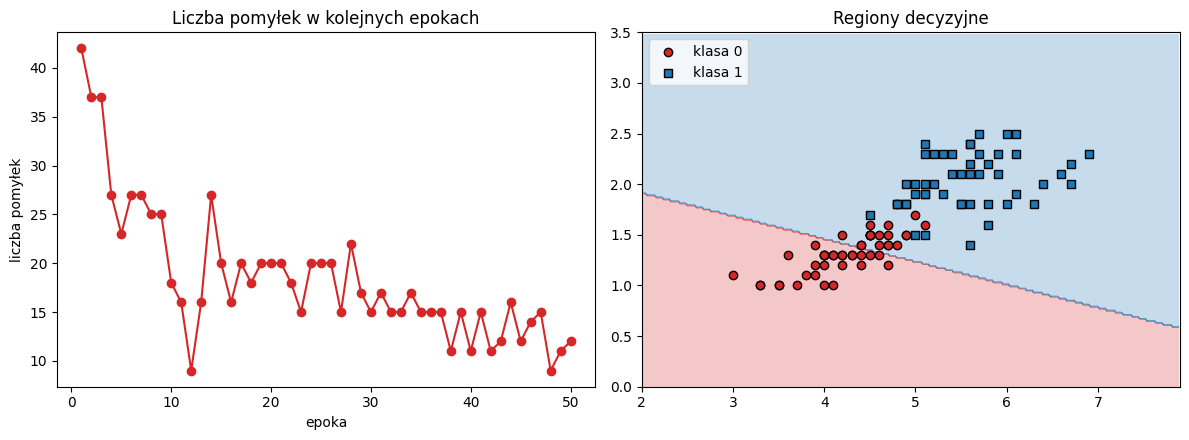

Historia pomyłek w ostatnich 10 epokach: [15, 11, 12, 16, 12, 14, 15, 9, 11, 12]
Liczba pomyłek ostatecznego modelu na całym zbiorze: 21


In [70]:
X3 = iris.data[50:][:, [2, 3]][idx]

ppn = Perceptron(eta=0.1, n_iter=50, w_init="zeros", verbose=False)
ppn.fit(X3, y2)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))

plot_decision_regions(X3, y2, ppn, ax=axs[1], title="Regiony decyzyjne")

axs[0].plot(range(1, len(ppn.errors_) + 1), ppn.errors_, marker="o", color="tab:red")
axs[0].set_xlabel("epoka")
axs[0].set_ylabel("liczba pomyłek")
axs[0].set_title("Liczba pomyłek w kolejnych epokach")

plt.tight_layout()
plt.show()

liczba_pomylek2 = (ppn.predict(X3) != y2).sum()
print(f"Historia pomyłek w ostatnich 10 epokach: {ppn.errors_[-10:]}")
print(f"Liczba pomyłek ostatecznego modelu na całym zbiorze: {liczba_pomylek2}")


1. * Klas nie da się rozdzielić prostą (na próbę zwiększyłam liczbę epok do aż 500 i dalej się nie udało, liczba pomyłek oscylowała wokół 4), lecz perceptron cały czas próbuje dalej, jednak, jak widzimy, liczba jego pomyłek jest dość wysoka i ciągle oscyluje (raz rośnie, raz się zmniejsza) i jest dwukrotnie większa na całym zbiorze niż jak to było w zadaniu 3.

2. * Wybór cech nie jest częścią uczenia. Cechy zostały wybrane przez nas i stanowią one zbiór danych, na których dopiero zostaje wykonywane uczenie.